# Task 63: Manual Adversarial Robustness Testing

Construct gradient-directed and boundary-directed perturbations for a scratch logistic classifier, compare with random noise, and quantify prediction changes.

Performance under input perturbations:


,accuracy,precision,recall,f1
scenario,,,,
clean,0.918,0.967,0.879,0.921
gradient sign,0.754,0.800,0.727,0.762
random Gaussian,0.918,1.000,0.848,0.918
boundary-directed,0.787,0.778,0.848,0.812


Clean accuracy: 0.918 gradient-perturbed: 0.754 prediction changes: 10 / 61


,Feature,Clean standardized,Adversarial standardized,Delta
2,cp,-0.973,-0.773,0.2
7,thalach,0.557,0.757,0.2
0,age,-0.305,-0.505,-0.2
3,trestbps,-0.190,-0.390,-0.2
1,sex,0.679,0.479,-0.2
4,chol,0.175,-0.025,-0.2
5,fbs,-0.391,-0.191,0.2
11,ca,0.329,0.129,-0.2
6,restecg,0.868,1.068,0.2
8,exang,1.446,1.246,-0.2


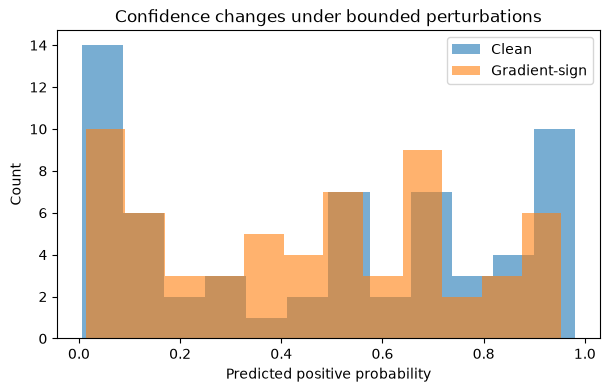

Stress tests are not clinically realistic: correlated features and ordinal categorical codes can be perturbed into invalid combinations.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_63_Adversarial_Robustness_Testing/heart.csv'),Path('Heart_Disease_Tasks/Task_63_Adversarial_Robustness_Testing/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train,test=split(y,.8,63);Xtr,Xte=X[train],X[test];ytr,yte=y[train],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xte=(Xtr-mean)/scale,(Xte-mean)/scale
class ManualLogistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1400):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
    def predict(self,x):return (self.proba(x)>=.5).astype(int)
model=ManualLogistic().fit(Xtr,ytr)
def score(ytrue,pred):
    tp=np.sum((ytrue==1)&(pred==1));tn=np.sum((ytrue==0)&(pred==0));fp=np.sum((ytrue==0)&(pred==1));fn=np.sum((ytrue==1)&(pred==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(ytrue),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}

lower,upper=np.quantile(Xtr,[.01,.99],axis=0);lower=np.minimum(lower,Xtr.min(0));upper=np.maximum(upper,Xtr.max(0))
epsilon=.2;clean_prob=model.proba(Xte);clean_pred=(clean_prob>=.5).astype(int)
# Increase binary cross-entropy using a signed input-gradient step.
gradient=((clean_prob-yte)*clean_prob*(1-clean_prob))[:,None]*model.w[None,:]
adversarial=np.clip(Xte+epsilon*np.sign(gradient),lower,upper)
adversarial_prob=model.proba(adversarial);adversarial_pred=(adversarial_prob>=.5).astype(int)
rng=np.random.default_rng(630);random_input=np.clip(Xte+rng.normal(0,epsilon,size=Xte.shape),lower,upper);random_pred=model.predict(random_input)
# Analytically move each point toward/across the linear model boundary.
scores=Xte@model.w+model.b;norm_sq=float(model.w@model.w);margin=np.maximum(np.abs(scores)+1e-4,1e-4)
boundary=np.clip(Xte-(np.sign(scores)*margin/max(norm_sq,1e-12))[:,None]*model.w[None,:],lower,upper);boundary_pred=model.predict(boundary)
results=pd.DataFrame([{'scenario':'clean',**score(yte,clean_pred)},{'scenario':'gradient sign',**score(yte,adversarial_pred)},{'scenario':'random Gaussian',**score(yte,random_pred)},{'scenario':'boundary-directed',**score(yte,boundary_pred)}]).set_index('scenario')
print('Performance under input perturbations:');display(results.round(3))
print('Clean accuracy:',round(score(yte,clean_pred)['accuracy'],3),'gradient-perturbed:',round(score(yte,adversarial_pred)['accuracy'],3),'prediction changes:',int(np.sum(adversarial_pred!=clean_pred)),'/',len(yte))
case=0
perturbation=pd.DataFrame({'Feature':features,'Clean standardized':Xte[case],'Adversarial standardized':adversarial[case],'Delta':adversarial[case]-Xte[case]}).sort_values('Delta',key=np.abs,ascending=False)
display(perturbation.round(3))
fig,ax=plt.subplots(figsize=(7,4));ax.hist(clean_prob,bins=12,alpha=.6,label='Clean');ax.hist(adversarial_prob,bins=12,alpha=.6,label='Gradient-sign')
ax.set_xlabel('Predicted positive probability');ax.set_ylabel('Count');ax.set_title('Confidence changes under bounded perturbations');ax.legend();plt.show()
print('Stress tests are not clinically realistic: correlated features and ordinal categorical codes can be perturbed into invalid combinations.')